In [15]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.svm import SVC

from sklearn.calibration import (
    CalibratedClassifierCV
)

from sklearn.ensemble import (
    VotingClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay
)

data = pd.read_csv(
    r"C:\Users\leoma\OneDrive\Documents\BasicEnsemblesDemo\ensemble_moons_demo.csv"
)

features = [
    "x1",
    "x2"
]

X = data[features]

y = data["class_label"]

print(
    data.shape,
    X.shape,
    y.shape
)

print(
    data.head()
)


(500, 3) (500, 2) (500,)
         x1        x2  class_label
0  0.831039 -0.258749            1
1  1.185064  0.920387            0
2  1.164022 -0.455526            1
3 -0.023656  1.086288            0
4  0.480503  1.509424            0


The dataset contains 500 rows.

The two inputs are x1 and x2.

The target is class_label.

Including class_label in X would leak the answer to the model and make the evaluation misleading.

In [16]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

assert X_dev.index.equals(y_dev.index)

assert X_test.index.equals(y_test.index)

assert set(X_dev.index).isdisjoint(
    X_test.index
)

print(
    X_dev.shape,
    X_test.shape
)

(400, 2) (100, 2)


The test set is hidden until the end so that model selection is performed using only the development data.

Using the test set during model selection would make the final evaluation less reliable.

x1             float64
x2             float64
class_label      int64
dtype: object
x1             0
x2             0
class_label    0
dtype: int64
           x1      x2  class_label
count  400.00  400.00        400.0
mean     0.49    0.26          0.5
std      0.91    0.61          0.5
min     -1.74   -1.25          0.0
25%     -0.13   -0.20          0.0
50%      0.44    0.27          0.5
75%      1.15    0.74          1.0
max      2.57    1.77          1.0
class_label
0    200
1    200
Name: count, dtype: int64
Majority rate: 0.5


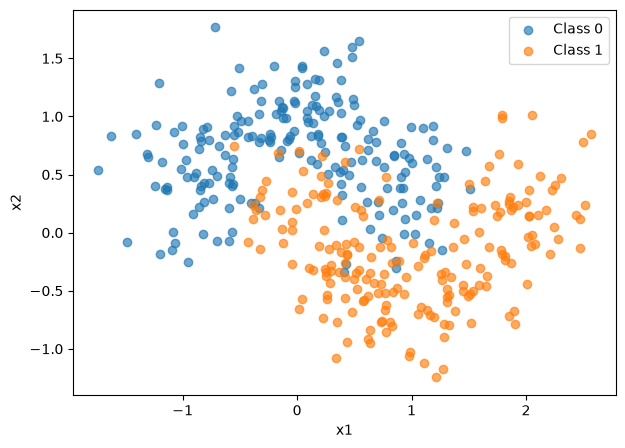

In [17]:
train = X_dev.copy()

train["class_label"] = y_dev

print(train.dtypes)

print(train.isna().sum())

print(train.describe().round(2))

print(y_dev.value_counts().sort_index())

print(
    "Majority rate:",
    y_dev.value_counts(
        normalize=True
    ).max()
)

plt.figure(
    figsize=(7, 5)
)

for label, group in train.groupby(
    "class_label"
):
    plt.scatter(
        group.x1,
        group.x2,
        label=f"Class {label}",
        alpha=0.65
    )

plt.xlabel("x1")
plt.ylabel("x2")

plt.legend()

plt.show()

There are no missing values in the development data.

The two classes appear relatively balanced.

A straight decision boundary may have difficulty separating the curved moon-shaped pattern shown in the scatter plot.

In [18]:
folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def cv_accuracy(model):
    scores = cross_val_score(
        model,
        X_dev,
        y_dev,
        cv=folds,
        scoring="accuracy"
    )
    return scores.mean(), scores.std()

baseline = DummyClassifier(
    strategy="most_frequent"
)

print(
    "Dummy CV mean and spread:",
    cv_accuracy(baseline)
)

Dummy CV mean and spread: (np.float64(0.5), np.float64(0.0))


The dummy classifier predicts the most common class.

The baseline gives us a reference point so we can compare whether more advanced models actually improve performance.

In [19]:
single_models = {
    "logistic":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "tree":
        DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ),

    "forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
}

for name, model in single_models.items():

    mean, spread = cv_accuracy(model)

    print(
        f"{name}: "
        f"{mean:.3f} ± {spread:.3f}"
    )

logistic: 0.842 ± 0.017
tree: 0.885 ± 0.024
forest: 0.905 ± 0.020


Different models can perform differently because they learn patterns in different ways.

Small differences between validation means do not automatically prove that one model is significantly better than another.

In [20]:
voters = [
    (
        "lr",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    ),

    (
        "rf",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    (
        "svc",
        CalibratedClassifierCV(
            SVC(
                random_state=42
            ),
            ensemble=False
        )
    )
]

hard_vote = VotingClassifier(
    estimators=voters,
    voting="hard"
)

soft_vote = VotingClassifier(
    estimators=voters,
    voting="soft"
)

for name, model in [
    ("hard", hard_vote),
    ("soft", soft_vote)
]:

    print(
        name,
        cv_accuracy(model)
    )

hard (np.float64(0.9099999999999999), np.float64(0.012247448713915915))
soft (np.float64(0.9175000000000001), np.float64(0.018708286933869722))


Hard voting uses the majority vote from the models.

Soft voting uses predicted probabilities from the models.

If several models make similar mistakes, voting may not improve performance very much because the errors are correlated.


In [21]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

bag.fit(
    X_dev,
    y_dev
)

print(
    "OOB accuracy:",
    round(
        bag.oob_score_,
        3
    )
)

print(
    "CV accuracy:",
    cv_accuracy(
        BaggingClassifier(
            estimator=DecisionTreeClassifier(
                random_state=42
            ),
            n_estimators=100,
            max_samples=0.8,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )
    )
)


OOB accuracy: 0.895
CV accuracy: (np.float64(0.9099999999999999), np.float64(0.019999999999999997))


Bagging trains many trees using bootstrap samples of the training data.

The out-of-bag score provides an estimate of model performance using observations that were not included in each bootstrap sample.

In [22]:
forest = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

forest.fit(
    X_dev,
    y_dev
)

print(
    "Forest OOB:",
    round(
        forest.oob_score_,
        3
    )
)

print(
    "Forest CV:",
    cv_accuracy(
        RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    )
)

print(
    dict(
        zip(
            features,
            forest.feature_importances_.round(3)
        )
    )
)

Forest OOB: 0.897
Forest CV: (np.float64(0.905), np.float64(0.020310096011589895))
{'x1': np.float64(0.435), 'x2': np.float64(0.565)}


Feature importance shows how much each feature contributed to the fitted forest.

A high importance value does not prove that a feature causes the outcome. It only shows that the model used the feature heavily when making predictions.

In [24]:
boost_models = {
    "AdaBoost":
        AdaBoostClassifier(
            n_estimators=100,
            learning_rate=0.5,
            random_state=42
        ),

    "HistGB":
        HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        )
}

for name, model in boost_models.items():

    print(
        name,
        cv_accuracy(model)
    )

AdaBoost (np.float64(0.905), np.float64(0.015000000000000027))
HistGB (np.float64(0.9025000000000001), np.float64(0.031024184114977132))
